<a href="https://colab.research.google.com/github/disiree31-abel/cs82a-portfolio/blob/main/Module_8_Lab_2_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd

df = pd.read_csv("lifecyclesavings.csv")

# Display the first five rows
display(df.head())

# Show the column names and data types
print(df.dtypes)

,Contry,sr,pop15,pop75,dpi,ddpi
0,Australia,11.43,29.35,2.87,2329.68,2.87
1,Austria,12.07,23.32,4.41,1507.99,3.93
2,Belgium,13.17,23.80,4.43,2108.47,3.82
3,Bolivia,5.75,41.89,1.67,189.13,0.22
4,Brazil,12.88,42.19,0.83,728.47,4.56


Contry     object
sr        float64
pop15     float64
pop75     float64
dpi       float64
ddpi      float64
dtype: object


In [2]:
# Dataset shape
print("Dataset shape:", df.shape)

# Missing values in each column
print("\nMissing values:")
print(df.isnull().sum())

# Mean of each numeric column
print("\nColumn means:")
print(df.select_dtypes(include="number").mean())

Dataset shape: (50, 6)

Missing values:
Contry    0
sr        0
pop15     0
pop75     0
dpi       0
ddpi      0
dtype: int64

Column means:
sr          9.6710
pop15      35.0896
pop75       2.2930
dpi      1106.7584
ddpi        3.7576
dtype: float64


,Contry,cluster
3,Bolivia,0
6,Chile,0
9,Costa Rica,0
8,Colombia,0
11,Ecuador,0
19,India,0
17,Honduras,0
16,Guatamala,0
23,Korea,0
30,Panama,0


Mean values by cluster:


,sr,pop15,pop75,dpi,ddpi
cluster,,,,,
0,6.14,44.56,1.08,337.15,2.36
1,13.59,37.49,1.62,483.24,7.66
2,10.90,26.74,3.50,1953.04,3.32


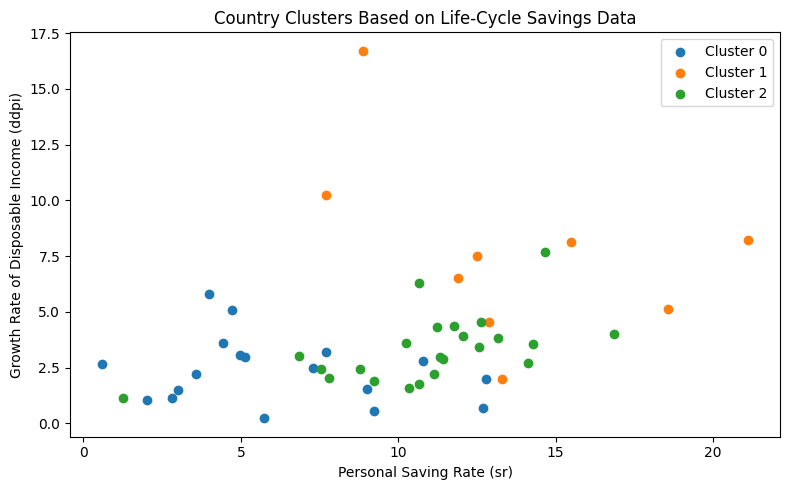

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# Keep the original dataset unchanged
clustered_df = df.copy()

# Select the numeric features, excluding country names
features = ["sr", "pop15", "pop75", "dpi", "ddpi"]
X = clustered_df[features]

# Standardize features because they use different scales
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Group countries into three clusters
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
clustered_df["cluster"] = kmeans.fit_predict(X_scaled)

# Display the countries assigned to each cluster
display(clustered_df[["Contry", "cluster"]].sort_values("cluster"))

# Compare original feature means by cluster
print("Mean values by cluster:")
display(clustered_df.groupby("cluster")[features].mean().round(2))

# Create a labeled chart using two features
plt.figure(figsize=(8, 5))
for cluster_id in sorted(clustered_df["cluster"].unique()):
    group = clustered_df[clustered_df["cluster"] == cluster_id]
    plt.scatter(
        group["sr"],
        group["ddpi"],
        label=f"Cluster {cluster_id}"
    )

plt.xlabel("Personal Saving Rate (sr)")
plt.ylabel("Growth Rate of Disposable Income (ddpi)")
plt.title("Country Clusters Based on Life-Cycle Savings Data")
plt.legend()
plt.tight_layout()
plt.show()

In [4]:
# Compare cluster 0 with the overall dataset
print("Overall feature means:")
print(df[features].mean().round(2))

print("\nCluster 0 feature means:")
print(
    clustered_df.loc[
        clustered_df["cluster"] == 0, features
    ].mean().round(2)
)

Overall feature means:
sr          9.67
pop15      35.09
pop75       2.29
dpi      1106.76
ddpi        3.76
dtype: float64

Cluster 0 feature means:
sr         6.14
pop15     44.56
pop75      1.08
dpi      337.15
ddpi       2.36
dtype: float64
